To-do list

Data Cleaning: 
- NA missing values
- Remove variables if needed (Duration)
- Dummy encode categorical variables
- Standardize numerical features

Exploratory Data Analysis: Colton McDonald
- Group Summary
- Cross tabulation
- Visualize the distributions

Feature Selection:
- Associations
- Correlations
- Group comparison

Modeling:
- Logistic regression
- Another appropriate method

Evaluation: 
- Depending on the results of the model


In [2]:
%pip install ucimlrepo

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
# metadata 
print(bank_marketing.metadata) 
  
# variable information 
print(bank_marketing.variables) 


Note: you may need to restart the kernel to use updated packages.
{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, '

In [12]:
import pandas as pd 

import os 

bank = pd.read_csv("bank.csv", sep=";") 

bank 

 

bank.isnull().sum() 

# no null values 

 

 

 

list(bank.columns) 

 

 

 

bank = bank[['age',  'job', 'marital', 'education', 'default',  'balance', 'housing',  'loan', 'contact', 'day',  'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']].copy() 

 

 

 

bank.columns = ['age',  'job', 'marital', 'education', 'default',  'balance', 'housing',  'loan', 'contact', 'day',  'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y'] 

# Removed duration since the information in not necessary and could be a data leak/security issue 

# Categorical to binary 

 

# housing 

print("housing category:", bank["housing"].nunique()) 

bank["housing"].value_counts() 

 

mapping = {cat: i for i, cat in enumerate(bank["housing"].unique())} 

print("label map:", mapping) 

bank["housing_new"] = bank["housing"].map(mapping) 

bank[["housing","housing_new"]].head() 

 

 

# default 

print("default category:", bank["default"].nunique()) 

bank["default"].value_counts() 

 

mapping = {cat: i for i, cat in enumerate(bank["default"].unique())} 

print("label map:", mapping) 

bank["def_new"] = bank["default"].map(mapping) 

bank[["default","def_new"]].head() 

 

# y 

print("y category:", bank["y"].nunique()) 

bank["y"].value_counts() 

 

 

mapping = {cat: i for i, cat in enumerate(bank["y"].unique())} 

print("label map:", mapping) 

bank["y_new"] = bank["y"].map(mapping) 

bank[["y","y_new"]].head() 

 

 

# looking at new columns 

bank.columns 

 

# removing old columns  

bank = bank[['age', 'job', 'marital', 'education', 'balance', 

       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 

       'poutcome', 'housing_new', 'def_new', 'y_new']] 

 

bank 

 

housing category: 2
label map: {'no': 0, 'yes': 1}
default category: 2
label map: {'no': 0, 'yes': 1}
y category: 2
label map: {'no': 0, 'yes': 1}


,age,job,marital,education,balance,loan,contact,day,month,campaign,pdays,previous,poutcome,housing_new,def_new,y_new
0,30,unemployed,married,primary,1787,no,cellular,19,oct,1,-1,0,unknown,0,0,0
1,33,services,married,secondary,4789,yes,cellular,11,may,1,339,4,failure,1,0,0
2,35,management,single,tertiary,1350,no,cellular,16,apr,1,330,1,failure,1,0,0
3,30,management,married,tertiary,1476,yes,unknown,3,jun,4,-1,0,unknown,1,0,0
4,59,blue-collar,married,secondary,0,no,unknown,5,may,1,-1,0,unknown,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,services,married,secondary,-333,no,cellular,30,jul,5,-1,0,unknown,1,0,0
4517,57,self-employed,married,tertiary,-3313,yes,unknown,9,may,1,-1,0,unknown,1,1,0
4518,57,technician,married,secondary,295,no,cellular,19,aug,11,-1,0,unknown,0,0,0
4519,28,blue-collar,married,secondary,1137,no,cellular,6,feb,4,211,3,other,0,0,0


Group Summary by Subscription Status (0=No, 1=Yes):
             age      balance        day  campaign      pdays  previous  \
y_new                                                                     
0      40.998000  1403.211750  15.948750  2.862250  36.006000  0.471250   
1      42.491363  1571.955854  15.658349  2.266795  68.639155  1.090211   

       housing_new   def_new  
y_new                         
0         0.584750  0.016750  
1         0.422265  0.017274  


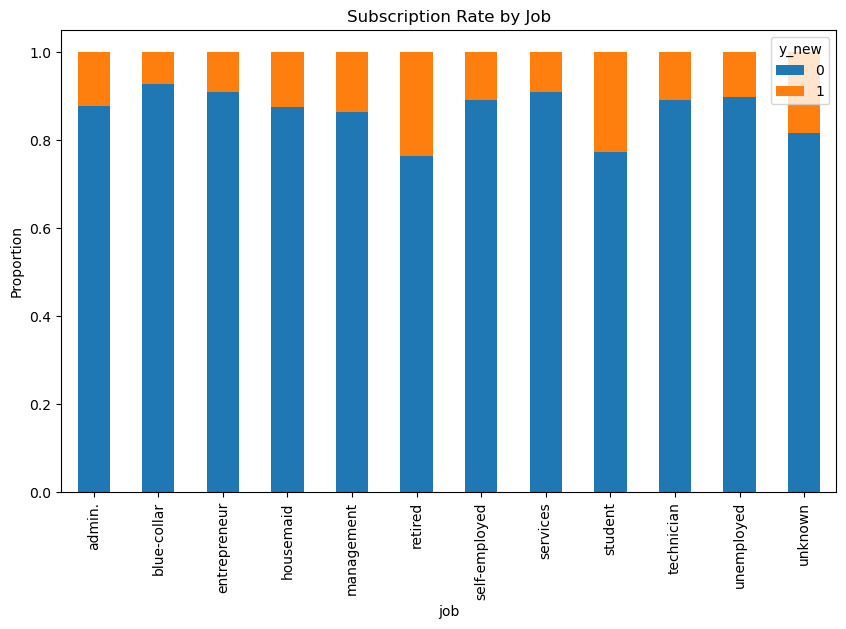

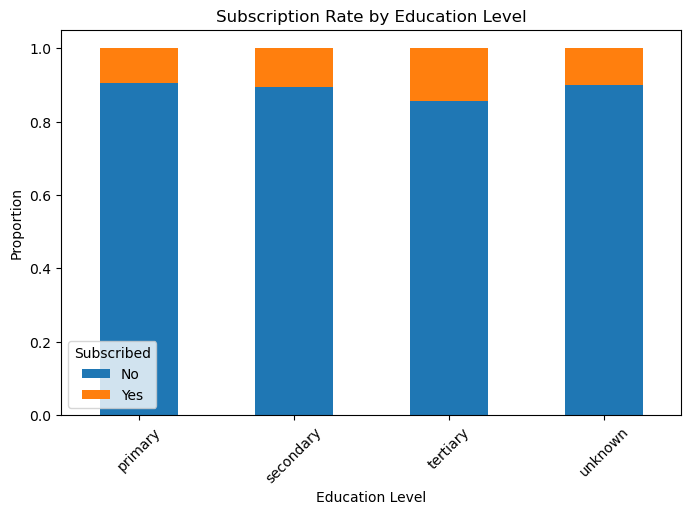

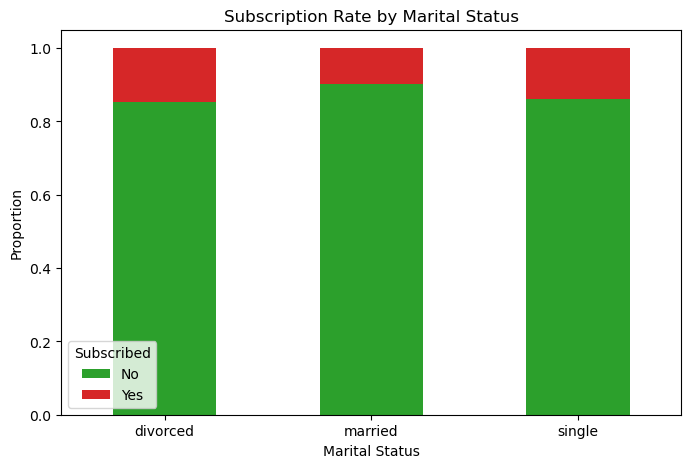

In [19]:
#my code 

import matplotlib.pyplot as plt
import seaborn as sns 

#Define the correct columns we're using
bank_cols_kept = ['age', 'job', 'marital', 'education', 'balance', 'loan', 
                  'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 
                  'poutcome', 'housing_new', 'def_new', 'y_new']

#Select columns using
bank = bank[bank_cols_kept].copy()

# Grouping by target 'y_new'
group_summary = bank.groupby('y_new').mean(numeric_only=True)
print("Group Summary by Subscription Status (0=No, 1=Yes):")
print(group_summary)

# Cross-tabulation using 'y_new'
job_crosstab = pd.crosstab(bank['job'], bank['y_new'], normalize='index')
job_crosstab.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Subscription Rate by Job')
plt.ylabel('Proportion')
plt.show()

#Cross-tabulation by plotting subscription rates by education
edu_crosstab = pd.crosstab(bank['education'], bank['y_new'], normalize='index')
edu_crosstab.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#1f77b4', '#ff7f0e'])
plt.title('Subscription Rate by Education Level')
plt.ylabel('Proportion')
plt.xlabel('Education Level')
plt.legend(title='Subscribed', labels=['No', 'Yes'])
plt.xticks(rotation=45)
plt.show()

# Cross-tabulation of Marital Status vs. Subscription
marital_crosstab = pd.crosstab(bank['marital'], bank['y_new'], normalize='index')
marital_crosstab.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#2ca02c', '#d62728'])
plt.title('Subscription Rate by Marital Status')
plt.ylabel('Proportion')
plt.xlabel('Marital Status')
plt.legend(title='Subscribed', labels=['No', 'Yes'])
plt.xticks(rotation=0)
plt.show()



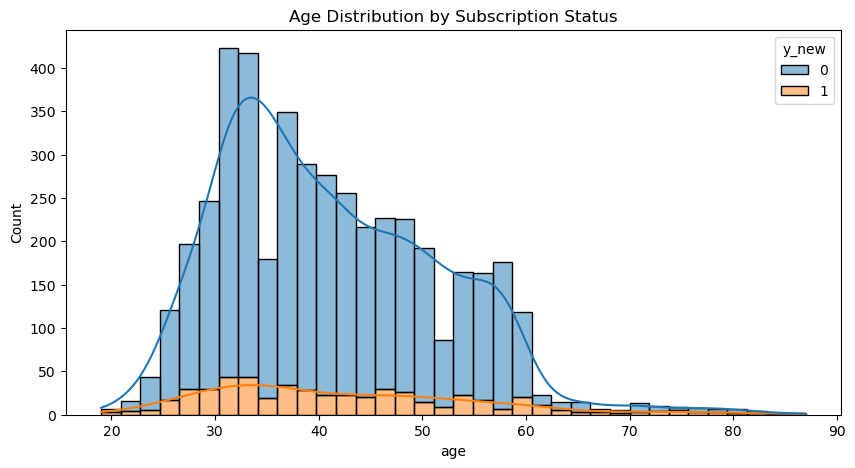

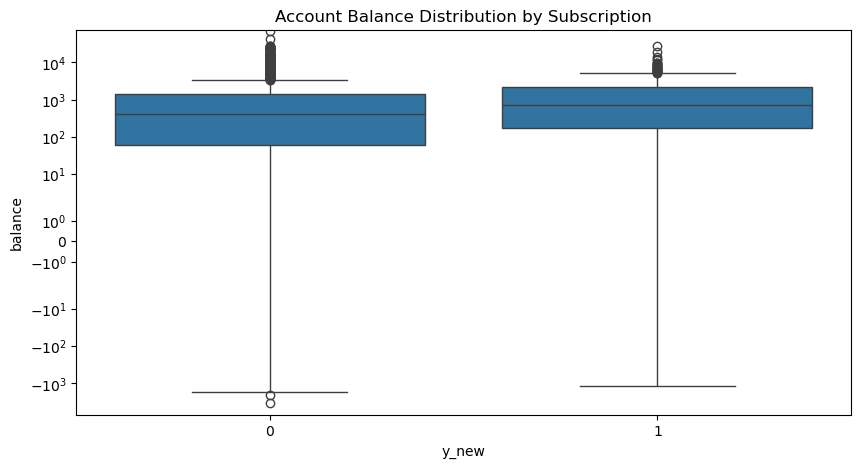

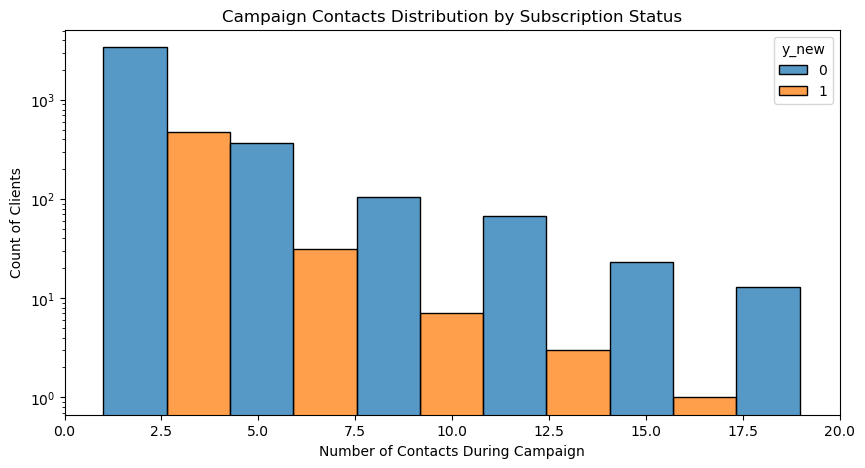

In [20]:
# Visualize Age distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=bank, x='age', hue='y_new', kde=True, multiple="stack")
plt.title('Age Distribution by Subscription Status')
plt.show()

# Visualize Balance distribution
plt.figure(figsize=(10, 5))
sns.boxplot(x='y_new', y='balance', data=bank)
plt.title('Account Balance Distribution by Subscription')
plt.yscale('symlog') 
plt.show()

# Visualize Campaign contacts distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=bank, x='campaign', hue='y_new', kde=False, multiple="dodge", bins=15)
plt.title('Campaign Contacts Distribution by Subscription Status')
plt.xlabel('Number of Contacts During Campaign')
plt.ylabel('Count of Clients')
plt.xlim(0, 20) # Limiting to 20 to focus on the main distribution
plt.yscale('log') # Log scale for better visibility of lower counts
plt.show()